# THỰC HÀNH LAB 2: CÁC THUẬT TOÁN PHÂN LỚP (CLASSIFICATION)
**Người thực hiện:** Tất Võ Tiến Nam - 3124411174  
**Mục tiêu:** 
1. Triển khai các giải thuật phân lớp: Cây quyết định (Decision Tree), Rừng cây (Random Forest), Support Vector Machine (SVM), và Naive Bayes.
2. Tự động dò tìm đường dẫn dữ liệu tránh lỗi `FileNotFoundError`.
3. Tự động lưu toàn bộ biểu đồ trực quan hóa vào thư mục `img/` nằm ở ngoài cùng (cùng cấp với `Code/` và `Data/`).

In [32]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# CẤU HÌNH ĐƯỜNG DẪN THƯ MỤC IMG/ NẰM Ở NGOÀI CÙNG (CÙNG CẤP VỚI CODE, DATA)
if os.path.basename(os.getcwd()).lower() == "code":
    IMG_DIR = os.path.join("..", "img")
else:
    IMG_DIR = "img"

os.makedirs(IMG_DIR, exist_ok=True)

# Hàm tự động dò tìm file dữ liệu linh hoạt
def find_dataset_path(folder_keywords, filename):
    possible_roots = [".", "Data", "../Data", ".."]
    for root in possible_roots:
        for r, dirs, files in os.walk(root):
            if any(kw.lower() in r.lower() for kw in folder_keywords):
                for f in files:
                    if f.lower() == filename.lower():
                        return os.path.join(r, f)
    for root in possible_roots:
        for r, dirs, files in os.walk(root):
            for f in files:
                if f.lower() == filename.lower():
                    return os.path.join(r, f)
    raise FileNotFoundError(f"Không thể tìm thấy file '{filename}' trong các thư mục {folder_keywords}")

print(f"✅ Thư mục lưu ảnh được thiết lập tại: '{os.path.abspath(IMG_DIR)}'")
print("✅ Đã khởi tạo xong các thư viện và hàm hỗ trợ dò tìm đường dẫn!")

✅ Thư mục lưu ảnh được thiết lập tại: 'c:\Machine-Learning\Tuan05\img'
✅ Đã khởi tạo xong các thư viện và hàm hỗ trợ dò tìm đường dẫn!


## 1. Cây quyết định và Rừng cây trên dữ liệu Titanic
* **Dataset:** `train.csv` (Thư mục Titanic)
* **Nhiệm vụ:** Tiền xử lý dữ liệu khuyết thiếu, xây dựng Decision Tree & Random Forest, lưu biểu đồ mức độ quan trọng của đặc trưng (Feature Importance).

Đang đọc dữ liệu Titanic từ: ../Data\Titanic\train.csv
Accuracy Decision Tree (Titanic): 0.7989
Accuracy Random Forest (Titanic): 0.8156


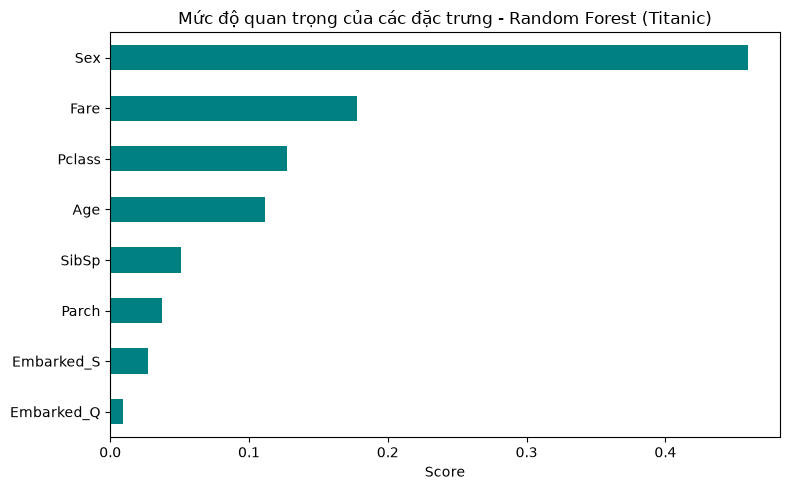

📷 Đã lưu biểu đồ vào: ..\img\titanic_rf_feature_importance.png


In [33]:
# 1. Tìm đường dẫn và nạp dữ liệu
titanic_path = find_dataset_path(["Titanic"], "train.csv")
print(f"Đang đọc dữ liệu Titanic từ: {titanic_path}")
df_titanic = pd.read_csv(titanic_path)

# 2. Tiền xử lý dữ liệu
df_titanic['Age'] = df_titanic['Age'].fillna(df_titanic['Age'].median())
df_titanic['Embarked'] = df_titanic['Embarked'].fillna(df_titanic['Embarked'].mode()[0])
df_titanic['Sex'] = df_titanic['Sex'].map({'male': 0, 'female': 1})
df_titanic = pd.get_dummies(df_titanic, columns=['Embarked'], drop_first=True)

features_t = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked_Q', 'Embarked_S']
X_t = df_titanic[features_t]
y_t = df_titanic['Survived']

# 3. Chia tập dữ liệu train/test (80:20)
X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(X_t, y_t, test_size=0.2, random_state=42)

# 4. Huấn luyện mô hình
dt_titanic = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_titanic.fit(X_train_t, y_train_t)
print(f"Accuracy Decision Tree (Titanic): {accuracy_score(y_test_t, dt_titanic.predict(X_test_t)):.4f}")

rf_titanic = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
rf_titanic.fit(X_train_t, y_train_t)
print(f"Accuracy Random Forest (Titanic): {accuracy_score(y_test_t, rf_titanic.predict(X_test_t)):.4f}")

# 5. Vẽ và lưu biểu đồ
plt.figure(figsize=(8, 5))
feat_imp = pd.Series(rf_titanic.feature_importances_, index=features_t).sort_values()
feat_imp.plot(kind='barh', color='teal')
plt.title('Mức độ quan trọng của các đặc trưng - Random Forest (Titanic)')
plt.xlabel('Score')
plt.tight_layout()

save_path_1 = os.path.join(IMG_DIR, "titanic_rf_feature_importance.png")
plt.savefig(save_path_1, dpi=300)
plt.show()
print(f"📷 Đã lưu biểu đồ vào: {save_path_1}")

## 2. Phân lớp và SVM trên tập dữ liệu Bệnh tiểu đường (Diabetes)
* **Dataset:** `diabetes_prediction_dataset.csv` (Thư mục Diabetes)
* **Nhiệm vụ:** Mã hóa biến chữ, chuẩn hóa thang đo bằng `StandardScaler`, huấn luyện Random Forest & SVM, xuất Confusion Matrix.

Đang đọc dữ liệu Diabetes từ: ../Data\Diabetes\diabetes_prediction_dataset.csv
Accuracy Random Forest (Diabetes): 0.9721
Accuracy SVM Linear (Diabetes): 0.9595


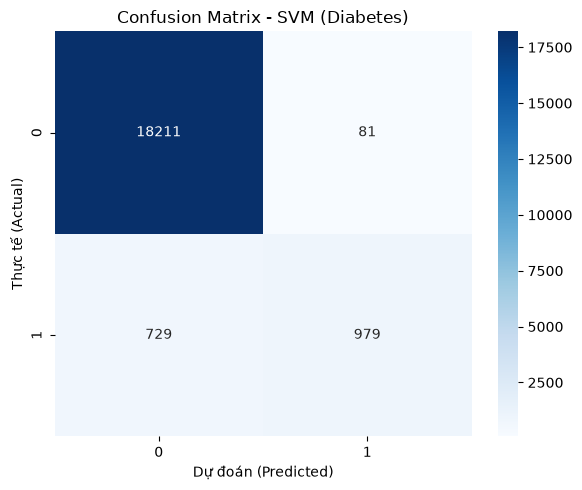

📷 Đã lưu biểu đồ vào: ..\img\diabetes_svm_confusion_matrix.png


In [34]:
# 1. Đọc dữ liệu Diabetes bằng hàm tự động dò đường dẫn
diab_path = find_dataset_path(["Diabetes"], "diabetes_prediction_dataset.csv")
print(f"Đang đọc dữ liệu Diabetes từ: {diab_path}")
df_diab = pd.read_csv(diab_path)

# 2. Tiền xử lý dữ liệu
le = LabelEncoder()
df_diab['gender'] = le.fit_transform(df_diab['gender'])
df_diab['smoking_history'] = le.fit_transform(df_diab['smoking_history'])

X_d = df_diab.drop('diabetes', axis=1)
y_d = df_diab['diabetes']

# Chuẩn hóa dữ liệu cho SVM
scaler = StandardScaler()
X_d_scaled = scaler.fit_transform(X_d)
X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(X_d_scaled, y_d, test_size=0.2, random_state=42)

# 3. Huấn luyện các mô hình
rf_diab = RandomForestClassifier(n_estimators=50, max_depth=5, random_state=42)
rf_diab.fit(X_train_d, y_train_d)
print(f"Accuracy Random Forest (Diabetes): {accuracy_score(y_test_d, rf_diab.predict(X_test_d)):.4f}")

svm_diab = SVC(kernel='linear', random_state=42)
svm_diab.fit(X_train_d, y_train_d)
y_pred_svm_d = svm_diab.predict(X_test_d)
print(f"Accuracy SVM Linear (Diabetes): {accuracy_score(y_test_d, y_pred_svm_d):.4f}")

# 4. Biểu diễn và lưu Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test_d, y_pred_svm_d), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - SVM (Diabetes)')
plt.xlabel('Dự đoán (Predicted)')
plt.ylabel('Thực tế (Actual)')
plt.tight_layout()

save_path_2 = os.path.join(IMG_DIR, "diabetes_svm_confusion_matrix.png")
plt.savefig(save_path_2, dpi=300)
plt.show()
print(f"📷 Đã lưu biểu đồ vào: {save_path_2}")

## 3. SVM trên tập dữ liệu Phân loại tình trạng động vật (Animal Condition Predict)
* **Dataset:** `data.csv` (Thư mục Animal-Condition-Predict)
* **Nhiệm vụ:** Tiền xử lý dữ liệu chuỗi, chuẩn hóa dữ liệu, huấn luyện mô hình SVM Kernel RBF.

Đang đọc dữ liệu Animal Condition từ: ../Data\Animal-Condition-Predict\data.csv
Accuracy SVM RBF (Animal Condition): 0.9886


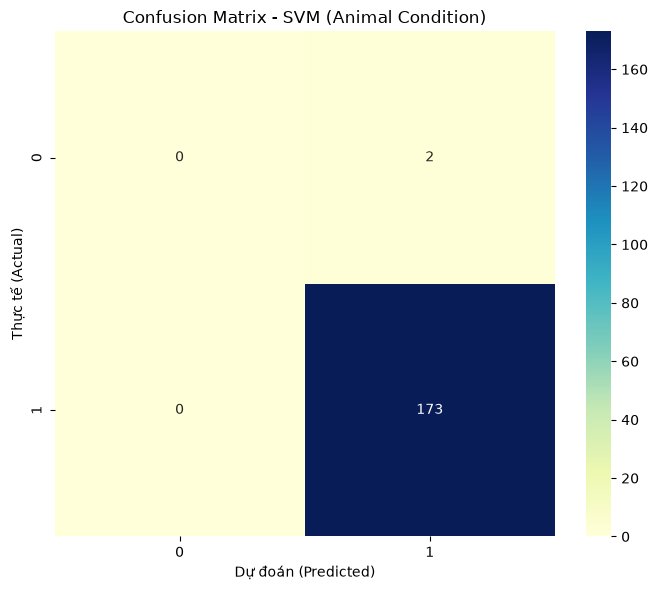

📷 Đã lưu biểu đồ vào: ..\img\animal_svm_confusion_matrix.png


In [35]:
# 1. Đọc dữ liệu bằng hàm dò đường dẫn
animal_path = find_dataset_path(["Animal"], "data.csv")
print(f"Đang đọc dữ liệu Animal Condition từ: {animal_path}")
df_animal = pd.read_csv(animal_path)

# 2. Xử lý triệt để giá trị khuyết và mã hóa 100% cột không phải dạng số
for col in df_animal.columns:
    if df_animal[col].isnull().sum() > 0:
        if pd.api.types.is_numeric_dtype(df_animal[col]):
            df_animal[col] = df_animal[col].fillna(df_animal[col].median())
        else:
            df_animal[col] = df_animal[col].fillna(df_animal[col].mode()[0])
            
    if not pd.api.types.is_numeric_dtype(df_animal[col]):
        df_animal[col] = LabelEncoder().fit_transform(df_animal[col].astype(str))

target_col_a = df_animal.columns[-1]
X_a = df_animal.drop(target_col_a, axis=1)
y_a = df_animal[target_col_a]

# 3. Chuẩn hóa và Phân chia tập dữ liệu
X_a_scaled = StandardScaler().fit_transform(X_a)
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(X_a_scaled, y_a, test_size=0.2, random_state=42)

# 4. Huấn luyện SVM Kernel RBF
svm_animal = SVC(kernel='rbf', C=1.0, random_state=42)
svm_animal.fit(X_train_a, y_train_a)
y_pred_svm_a = svm_animal.predict(X_test_a)
print(f"Accuracy SVM RBF (Animal Condition): {accuracy_score(y_test_a, y_pred_svm_a):.4f}")

# 5. Vẽ và lưu Confusion Matrix
plt.figure(figsize=(7, 6))
sns.heatmap(confusion_matrix(y_test_a, y_pred_svm_a), annot=True, fmt='d', cmap='YlGnBu')
plt.title('Confusion Matrix - SVM (Animal Condition)')
plt.xlabel('Dự đoán (Predicted)')
plt.ylabel('Thực tế (Actual)')
plt.tight_layout()

save_path_3 = os.path.join(IMG_DIR, "animal_svm_confusion_matrix.png")
plt.savefig(save_path_3, dpi=300)
plt.show()
print(f"📷 Đã lưu biểu đồ vào: {save_path_3}")

## 4. Naive Bayes trên dữ liệu Hành vi khách hàng (Customer Behaviour Prediction)
* **Dataset:** `Customer_Behaviour.csv` (Thư mục Customer Behaviour Prediction)
* **Nhiệm vụ:** Áp dụng mô hình Gaussian Naive Bayes để phân loại hành vi mua hàng.

Đang đọc dữ liệu Customer Behaviour từ: ../Data\Customer Behaviour Prediction( Naive Bayes)\Customer_Behaviour.csv
Accuracy Gaussian Naive Bayes (Customer Behaviour): 0.9375

Báo cáo phân loại chi tiết:
              precision    recall  f1-score   support

           0       0.94      0.96      0.95        52
           1       0.93      0.89      0.91        28

    accuracy                           0.94        80
   macro avg       0.93      0.93      0.93        80
weighted avg       0.94      0.94      0.94        80



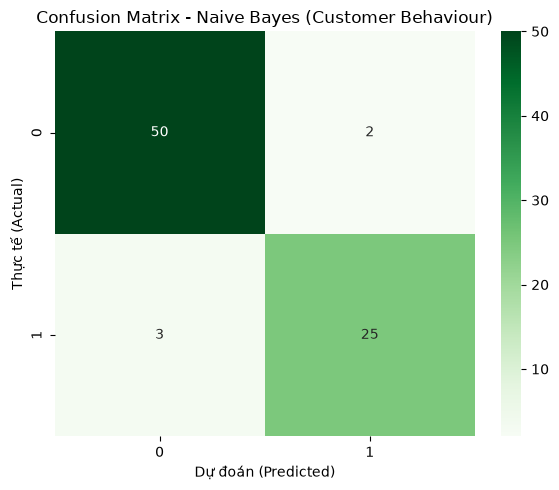

📷 Đã lưu biểu đồ vào: ..\img\customer_nb_confusion_matrix.png


In [36]:
# 1. Đọc dữ liệu bằng hàm dò đường dẫn
cust_path = find_dataset_path(["Customer"], "Customer_Behaviour.csv")
print(f"Đang đọc dữ liệu Customer Behaviour từ: {cust_path}")
df_cust = pd.read_csv(cust_path)

# 2. Tiền xử lý
if 'User ID' in df_cust.columns:
    df_cust = df_cust.drop('User ID', axis=1)

if 'Gender' in df_cust.columns:
    df_cust['Gender'] = df_cust['Gender'].map({'Male': 0, 'Female': 1})

X_c = df_cust.drop('Purchased', axis=1)
y_c = df_cust['Purchased']

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_c, y_c, test_size=0.2, random_state=42)

# 3. Huấn luyện Gaussian Naive Bayes
nb_cust = GaussianNB()
nb_cust.fit(X_train_c, y_train_c)
y_pred_nb_c = nb_cust.predict(X_test_c)

print(f"Accuracy Gaussian Naive Bayes (Customer Behaviour): {accuracy_score(y_test_c, y_pred_nb_c):.4f}")
print("\nBáo cáo phân loại chi tiết:")
print(classification_report(y_test_c, y_pred_nb_c))

# 4. Trực quan hóa Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test_c, y_pred_nb_c), annot=True, fmt='d', cmap='Greens')
plt.title('Confusion Matrix - Naive Bayes (Customer Behaviour)')
plt.xlabel('Dự đoán (Predicted)')
plt.ylabel('Thực tế (Actual)')
plt.tight_layout()

save_path_4 = os.path.join(IMG_DIR, "customer_nb_confusion_matrix.png")
plt.savefig(save_path_4, dpi=300)
plt.show()
print(f"📷 Đã lưu biểu đồ vào: {save_path_4}")

## 5. Categorical Naive Bayes trên dữ liệu Phân loại nấm (Mushroom Classification)
* **Dataset:** `mushrooms.csv` (Thư mục Mushroom Classification)
* **Nhiệm vụ:** Áp dụng thuật toán Categorical Naive Bayes trên thuộc tính định tính.

Đang đọc dữ liệu Mushroom từ: ../Data\Mushroom Classification\mushrooms.csv
Accuracy Categorical Naive Bayes (Mushroom): 0.9508


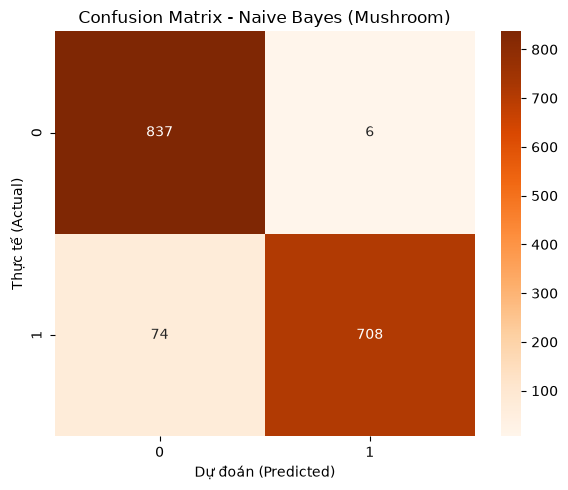

📷 Đã lưu biểu đồ vào: ..\img\mushroom_nb_confusion_matrix.png


In [37]:
# 1. Đọc dữ liệu bằng hàm dò đường dẫn
shroom_path = find_dataset_path(["Mushroom"], "mushrooms.csv")
print(f"Đang đọc dữ liệu Mushroom từ: {shroom_path}")
df_shroom = pd.read_csv(shroom_path)

# 2. Mã hóa các biến thuộc tính chữ sang số
for col in df_shroom.columns:
    df_shroom[col] = LabelEncoder().fit_transform(df_shroom[col])

X_m = df_shroom.drop('class', axis=1)
y_m = df_shroom['class']

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(X_m, y_m, test_size=0.2, random_state=42)

# 3. Huấn luyện Categorical Naive Bayes
cnb_shroom = CategoricalNB()
cnb_shroom.fit(X_train_m, y_train_m)
y_pred_cnb = cnb_shroom.predict(X_test_m)

print(f"Accuracy Categorical Naive Bayes (Mushroom): {accuracy_score(y_test_m, y_pred_cnb):.4f}")

# 4. Trực quan hóa Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test_m, y_pred_cnb), annot=True, fmt='d', cmap='Oranges')
plt.title('Confusion Matrix - Naive Bayes (Mushroom)')
plt.xlabel('Dự đoán (Predicted)')
plt.ylabel('Thực tế (Actual)')
plt.tight_layout()

save_path_5 = os.path.join(IMG_DIR, "mushroom_nb_confusion_matrix.png")
plt.savefig(save_path_5, dpi=300)
plt.show()
print(f"📷 Đã lưu biểu đồ vào: {save_path_5}")